# Activity 1: Ecommerce Customer Spending Prediction using Multiple Linear Regression
**Objective:** Explain and predict yearly customer spending using multiple numerical features, compare with simpler models and check regression assumptions.

**Problem statement:** As an e-commerce data analyst, I want to estimate customer spending and help the management team understand which customer behaviours are associated with spending. The main success metric is test RMSE because it expresses typical prediction error in spending units and penalises large errors.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


In [2]:
import sklearn
import matplotlib

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

Pandas: 2.3.3
NumPy: 2.4.0
Scikit-learn: 1.8.0
Matplotlib: 3.10.8
Seaborn: 0.13.2


In [3]:
df = pd.read_csv('Ecommerce Customers.csv')

In [4]:
df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [5]:
df.shape

(500, 8)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [7]:
df.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [8]:
df.isna().sum()

Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

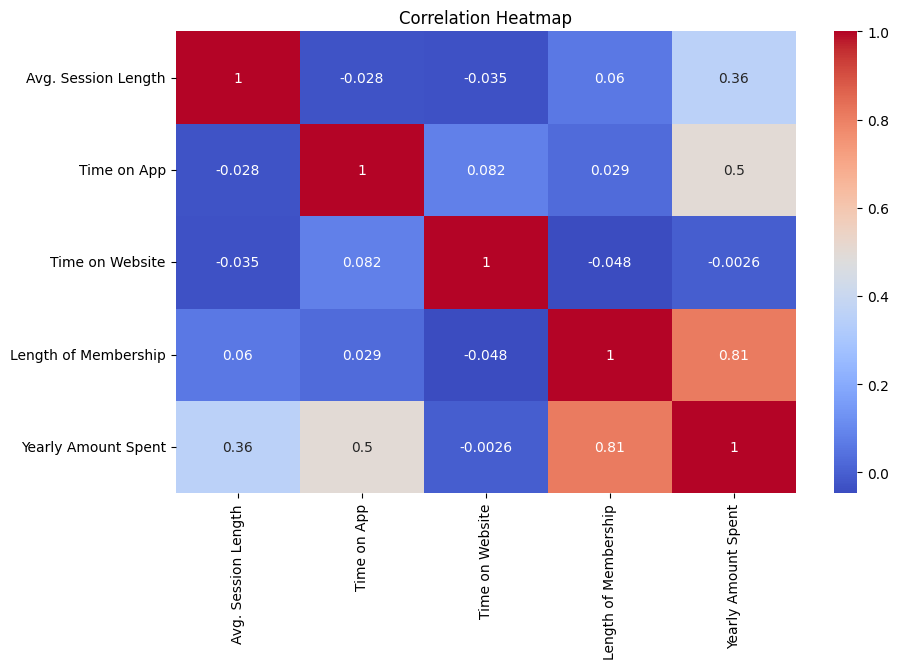

In [10]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

Length of Membership has the strongest positive correlation with spending (about 0.81), followed by Time on App (0.50) and Avg. Session Length (0.36). Time on Website has almost zero marginal correlation. Input correlations are weak, suggesting little redundancy. Correlation does not prove causation.

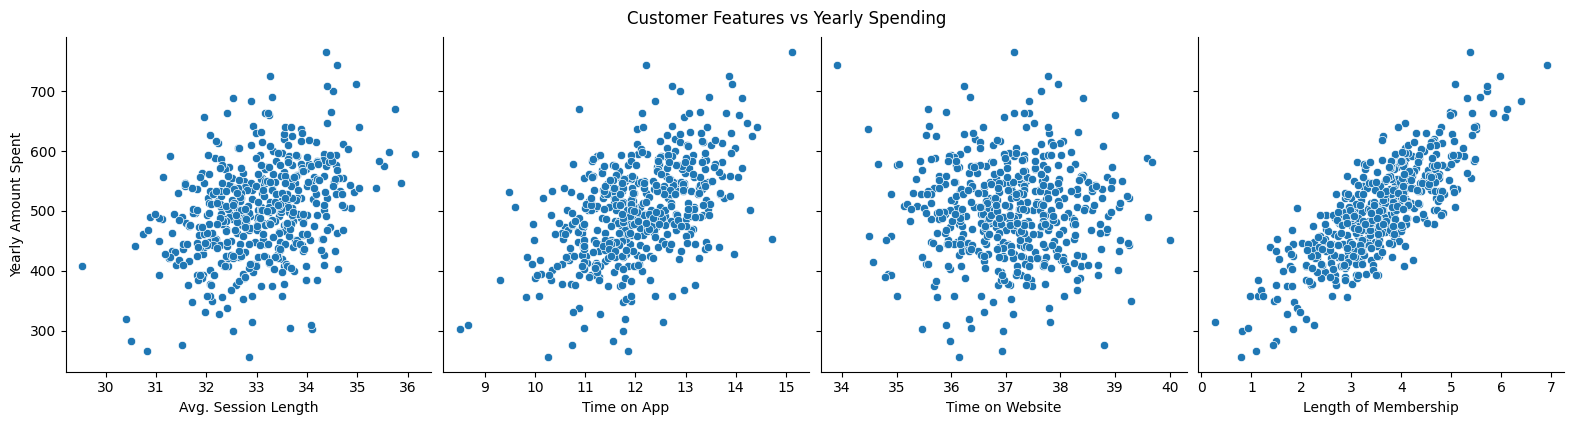

In [11]:
g = sns.pairplot(
    df,
    x_vars=[
        'Avg. Session Length',
        'Time on App',
        'Time on Website',
        'Length of Membership'
    ],
    y_vars=['Yearly Amount Spent'],
    height=4,
    aspect=1
)

g.figure.suptitle('Customer Features vs Yearly Spending', y=1.04)
plt.show()

The pair plots show a clear positive trend for membership length and app time, a weaker positive trend for session length, and little visible linear trend for website time. The four-feature linear model will test their combined predictive value.

In [12]:
X = df[
    [
        'Avg. Session Length',
        'Time on App',
        'Time on Website',
        'Length of Membership'
    ]
]

y = df['Yearly Amount Spent']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


## Manual calculation worksheet (five training observations)
Use Time on App and Length of Membership because they have strong relationships with spending. To avoid using test data, take five training rows. The design matrix includes a column of ones for the intercept. The following worksheet displays the individual products, their sums, the inverse and the coefficient calculation.

In [14]:
# Select five observations and two features
sample = X_train[['Time on App', 'Length of Membership']].head(5).round(4)
sample_y = y_train.loc[sample.index].round(4)

worksheet = sample.copy()
worksheet['Yearly Amount Spent'] = sample_y
display(worksheet)

# Design matrix and target vector
A = np.column_stack([np.ones(5), sample.values])
v = sample_y.values

print("Design Matrix X:\n", A)
print("\nTarget Vector y:\n", v)

# Intermediate calculations
x1 = A[:, 1]
x2 = A[:, 2]

products = pd.DataFrame({
    'x1': x1,
    'x2': x2,
    'y': v,
    'x1²': x1 * x1,
    'x2²': x2 * x2,
    'x1*x2': x1 * x2,
    'x1*y': x1 * v,
    'x2*y': x2 * v
})

display(products.round(6))
print("Sum of Products:")
print(products.sum().round(6))

# Calculate X transpose X and X transpose y
XtX = A.T @ A
Xty = A.T @ v

print("\nX transpose X:\n", XtX)
print("\nX transpose y:\n", Xty)

# Calculate inverse and coefficients
inverse = np.linalg.inv(XtX)
beta = inverse @ Xty

print("\nInverse Matrix:\n", inverse)
print("\nIntercept:", beta[0])
print("Coefficient b1:", beta[1])
print("Coefficient b2:", beta[2])

# Fitted equation
print(f"\nEquation: y = {beta[0]:.4f} + {beta[1]:.4f}x1 + {beta[2]:.4f}x2")

# Prediction and residual
manual_prediction = A[0] @ beta

print("\nActual Value:", v[0])
print("Predicted Value:", manual_prediction)
print("Residual:", v[0] - manual_prediction)

,Time on App,Length of Membership,Yearly Amount Spent
249,11.9176,3.6350,518.7865
433,11.8227,2.1174,434.1442
19,13.9896,4.0645,605.0610
322,10.7321,4.0866,478.2621
332,11.7370,2.1901,424.2028


Design Matrix X:
 [[ 1.     11.9176  3.635 ]
 [ 1.     11.8227  2.1174]
 [ 1.     13.9896  4.0645]
 [ 1.     10.7321  4.0866]
 [ 1.     11.737   2.1901]]

Target Vector y:
 [518.7865 434.1442 605.061  478.2621 424.2028]


,x1,x2,y,x1²,x2²,x1*x2,x1*y,x2*y
0,11.9176,3.6350,518.7865,142.029190,13.213225,43.320476,6182.689992,1885.788928
1,11.8227,2.1174,434.1442,139.776235,4.483383,25.033385,5132.756633,919.256929
2,13.9896,4.0645,605.0610,195.708908,16.520160,56.860729,8464.561366,2459.270434
3,10.7321,4.0866,478.2621,115.177970,16.700300,43.857800,5132.756683,1954.465898
4,11.7370,2.1901,424.2028,137.757169,4.796538,25.705204,4978.868264,929.046552


Sum of Products:
x1          60.199000
x2          16.093600
y         2460.456600
x1²        730.449473
x2²         55.713606
x1*x2      194.777594
x1*y     29891.632938
x2*y      8147.828741
dtype: float64

X transpose X:
 [[  5.          60.199       16.0936    ]
 [ 60.199      730.44947262 194.77759374]
 [ 16.0936     194.77759374  55.71360558]]

X transpose y:
 [ 2460.4566     29891.63293835  8147.82874122]

Inverse Matrix:
 [[26.08912994 -2.07405241 -0.28519215]
 [-2.07405241  0.18508771 -0.04795899]
 [-0.28519215 -0.04795899  0.26799748]]

Intercept: -129.3383239626599
Coefficient b1: 38.696209595284536
Coefficient b2: 48.322009891311694

Equation: y = -129.3383 + 38.6962x1 + 48.3220x2

Actual Value: 518.7865
Predicted Value: 507.4781294650211
Residual: 11.308370534978962


In [15]:
manual_model = LinearRegression().fit(sample, sample_y)

library_beta = np.r_[manual_model.intercept_, manual_model.coef_]

comparison = pd.DataFrame({
    "Manual": beta,
    "Library": library_beta,
    "Difference": beta - library_beta
}, index=["Intercept", "Time on App", "Length of Membership"])

display(comparison)

print("Agreement:", np.allclose(beta, library_beta))

,Manual,Library,Difference
Intercept,-129.338324,-129.338324,8.697043e-12
Time on App,38.696210,38.696210,7.105427e-15
Length of Membership,48.322010,48.322010,2.913225e-13


Agreement: True


## Mean benchmark and single-feature baseline
Use only training data to calculate the mean and select the strongest feature. Both baselines are evaluated on the same unseen test records as the multiple model.

In [16]:
mean_pred = np.full(len(y_test), y_train.mean())
best_feature = X_train.corrwith(y_train).abs().idxmax()
print('Selected feature:', best_feature)
single_model = LinearRegression()
single_model.fit(X_train[[best_feature]], y_train)
y_pred_single = single_model.predict(X_test[[best_feature]])
print('Mean benchmark R2:', r2_score(y_test, mean_pred))
print('Single model intercept:', single_model.intercept_)
print('Single model coefficient:', single_model.coef_[0])
print('Single model test R2:', r2_score(y_test, y_pred_single))

Selected feature: Length of Membership
Mean benchmark R2: -0.036211019877467665
Single model intercept: 271.3521128033931
Single model coefficient: 64.64010065386708
Single model test R2: 0.5633624502240147


In [17]:
model = LinearRegression()

In [18]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [19]:
coeff_df = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient'])
print(coeff_df)

                      Coefficient
Avg. Session Length     25.596259
Time on App             38.785346
Time on Website          0.310386
Length of Membership    61.896829


In [20]:
print("Intercept:", round(model.intercept_, 4))

print("\nRegression Equation:")
print(f"y = {model.intercept_:.4f} + "
      f"({model.coef_[0]:.4f} × {X.columns[0]}) + "
      f"({model.coef_[1]:.4f} × {X.columns[1]}) + "
      f"({model.coef_[2]:.4f} × {X.columns[2]}) + "
      f"({model.coef_[3]:.4f} × {X.columns[3]})")

standardised = model.coef_ * X_train.std() / y_train.std()

print("\nStandardised Coefficients:")
print(standardised.round(4))

Intercept: -1044.2574

Regression Equation:
y = -1044.2574 + (25.5963 × Avg. Session Length) + (38.7853 × Time on App) + (0.3104 × Time on Website) + (61.8968 × Length of Membership)

Standardised Coefficients:
Avg. Session Length     0.3114
Time on App             0.4773
Time on Website         0.0039
Length of Membership    0.7837
dtype: float64


In [21]:
y_pred = model.predict(X_test)

In [22]:
comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred, 'Residual': y_test.values - y_pred})
display(comparison.head(10).round(4))

,Actual,Predicted,Residual
0,401.0331,402.8623,-1.8292
1,534.7772,542.5333,-7.7561
2,418.6027,426.6201,-8.0174
3,503.9784,501.9139,2.0645
4,410.0696,409.6667,0.4030
5,557.6083,569.9216,-12.3133
6,538.9420,531.5042,7.4377
7,514.3366,505.9431,8.3935
8,408.6202,408.1038,0.5164
9,475.0154,473.4594,1.5560


Positive residuals indicate underprediction; negative residuals indicate overprediction. The sample shows that predictions are generally close but not identical to actual spending.

In [23]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

n = len(y_test)
p = X_test.shape[1]

adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

In [24]:
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R2 Score:", round(r2, 4))
print("Adjusted R2 Score:", round(adjusted_r2, 4))

Mean Absolute Error (MAE): 8.5584
Mean Squared Error (MSE): 109.8637
Root Mean Squared Error (RMSE): 10.4816
R2 Score: 0.9778
Adjusted R2 Score: 0.9769


In [25]:
# Mean baseline metrics
mean_mae = mean_absolute_error(y_test, mean_pred)
mean_mse = mean_squared_error(y_test, mean_pred)
mean_rmse = np.sqrt(mean_mse)
mean_r2 = r2_score(y_test, mean_pred)

# Single Linear Regression metrics
single_mae = mean_absolute_error(y_test, y_pred_single)
single_mse = mean_squared_error(y_test, y_pred_single)
single_rmse = np.sqrt(single_mse)
single_r2 = r2_score(y_test, y_pred_single)

single_adjusted_r2 = 1 - (1 - single_r2) * (n - 1) / (n - 2)

# Model comparison
results = pd.DataFrame({
    'Model': ['Mean Baseline', 'Single Linear Regression', 'Multiple Linear Regression'],
    'MAE': [mean_mae, single_mae, mae],
    'MSE': [mean_mse, single_mse, mse],
    'RMSE': [mean_rmse, single_rmse, rmse],
    'R2': [mean_r2, single_r2, r2],
    'Adjusted R2': [mean_r2, single_adjusted_r2, adjusted_r2]
})

display(results.round(4))

,Model,MAE,MSE,RMSE,R2,Adjusted R2
0,Mean Baseline,54.9108,5131.0381,71.6313,-0.0362,-0.0362
1,Single Linear Regression,37.8362,2162.1116,46.4985,0.5634,0.5589
2,Multiple Linear Regression,8.5584,109.8637,10.4816,0.9778,0.9769


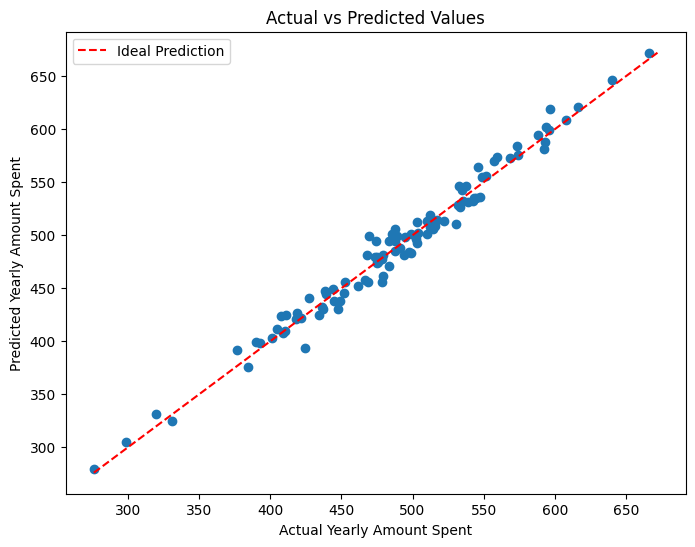

In [26]:
# Actual vs predicted visualization
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Yearly Amount Spent')
plt.ylabel('Predicted Yearly Amount Spent')

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], 'r--', label='Ideal Prediction')
plt.legend()
plt.title('Actual vs Predicted Values')

plt.show()

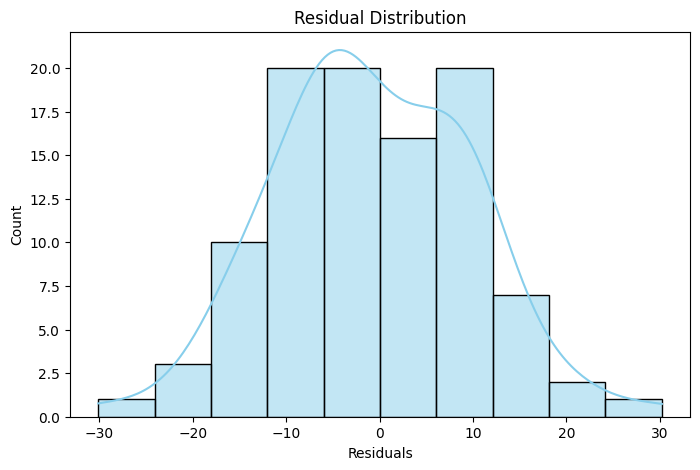

In [27]:
# Residual analysis
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True, color="skyblue")

plt.title('Residual Distribution')
plt.xlabel('Residuals')

plt.show()

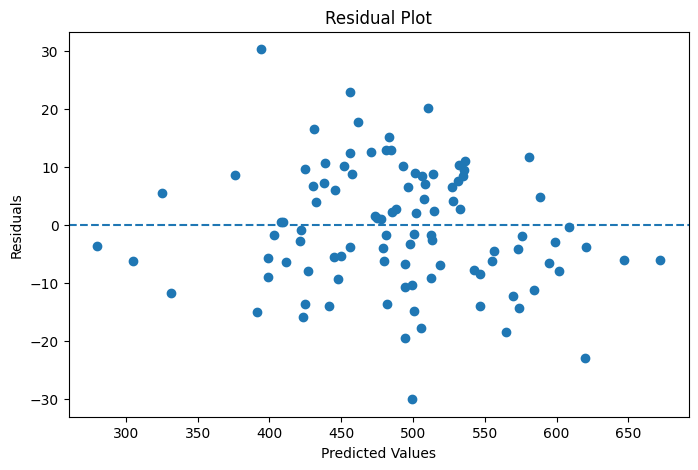

In [28]:
# Residuals against Predicted Values:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

plt.title('Residual Plot')

plt.show()

In [29]:
X_vif = add_constant(X_train)

vif = pd.DataFrame()
vif['Feature'] = X_train.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(1, X_vif.shape[1])
]

display(vif.round(4))

print("Residual Skewness:", round(residuals.skew(), 4))
print("Largest Absolute Residual:", round(residuals.abs().max(), 4))

,Feature,VIF
0,Avg. Session Length,1.0021
1,Time on App,1.0103
2,Time on Website,1.0086
3,Length of Membership,1.0061


Residual Skewness: 0.0763
Largest Absolute Residual: 30.2296


In [30]:
new_customer = pd.DataFrame({
    'Avg. Session Length': [34.5],
    'Time on App': [12.5],
    'Time on Website': [37.0],
    'Length of Membership': [4.0]
})

prediction = model.predict(new_customer)

print("Predicted Yearly Spending:", round(prediction[0], 2))

print("\nNew Customer:")
display(new_customer)

Predicted Yearly Spending: 582.7

New Customer:


,Avg. Session Length,Time on App,Time on Website,Length of Membership
0,34.5,12.5,37.0,4.0


## Conclusion and limitations
The four-feature model improves on the mean and single-feature baselines. Membership length and app time show the strongest predictive associations. The model may help with aggregate spending forecasts but should not be used alone for individual pricing or exclusion decisions. Incorrect predictions could misdirect marketing resources. Other factors and nonlinear effects may matter, and future customers may differ from this dataset. Adding features does not always improve a model. Predictions are estimates, not guarantees. The source's collection details and currency are uncertain; personal-looking fields should not be published unless permitted.